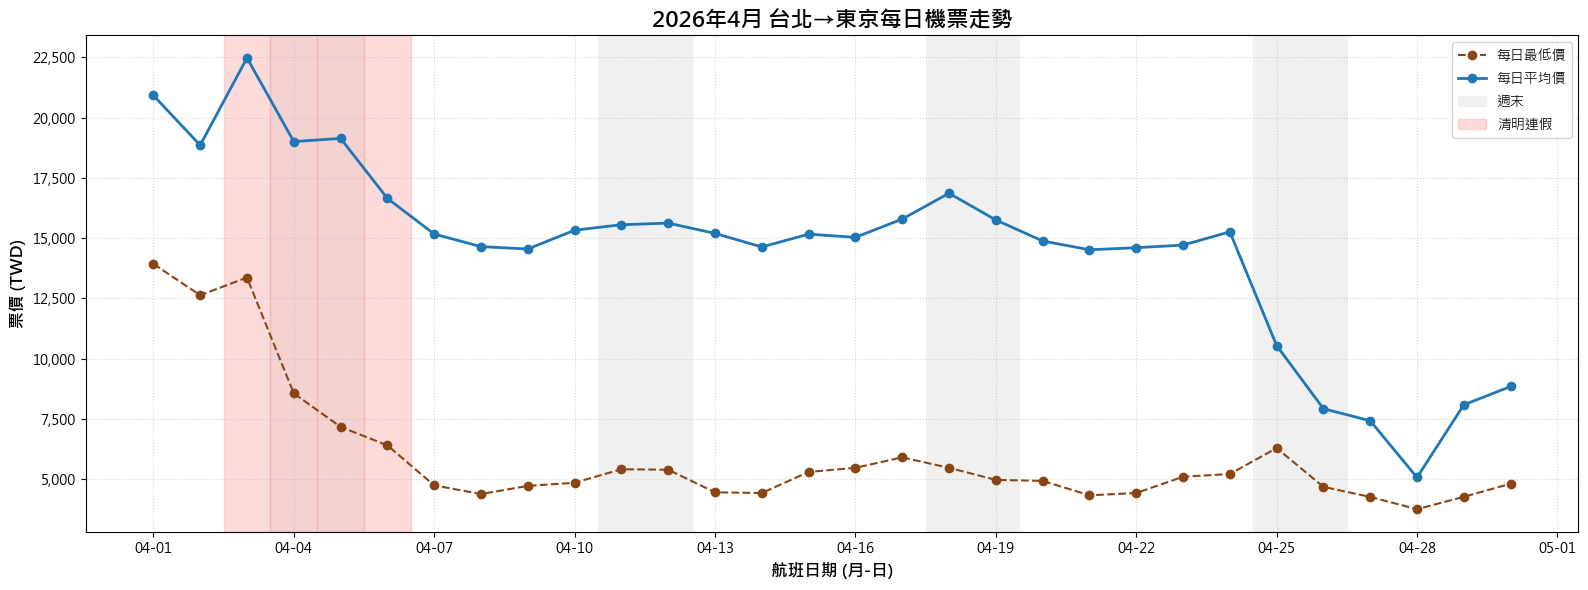

In [35]:
#2026年4月 台北→東京每日機票走勢

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.patches as mpatches

# 環境設定
plt.rcParams['font.sans-serif'] = ['Microsoft JhengHei']
plt.rcParams['axes.unicode_minus'] = False

# 資料處理
df = pd.read_csv('台北_東京_經濟艙直飛.csv')
df['date'] = pd.to_datetime(df['date'])
df_apr = df[df['date'].dt.month == 4].copy()
df_daily = df_apr.groupby('date')['ticket_price'].agg(['min', 'mean']).reset_index()

# 建立畫布
plt.figure(figsize=(16, 6))

# 繪製底色 (週末與連假)
all_days = pd.date_range(start='2026-04-01', end='2026-04-30')
for d in all_days:
    # 週末底色 (週六、日)
    if d.dayofweek >= 5:
        plt.axvspan(d - pd.Timedelta(days=0.5), d + pd.Timedelta(days=0.5), 
                    color='#F0F0F0', alpha=1.0, zorder=0)
    # 清明連假底色 (4/3 ~ 4/6)
    if pd.to_datetime('2026-04-03') <= d <= pd.to_datetime('2026-04-06'):
        plt.axvspan(d - pd.Timedelta(days=0.5), d + pd.Timedelta(days=0.5), 
                    color='#FCA5A5', alpha=0.4, zorder=1)

# 繪製折線
plt.plot(df_daily['date'], df_daily['min'], color='#8B4513', marker='o', linestyle='--', label='每日最低價', zorder=3)
plt.plot(df_daily['date'], df_daily['mean'], color='#1f77b4', marker='o', linestyle='-', linewidth=2, label='每日平均價', zorder=3)

# 設定座標軸與標題
plt.title('2026年4月 台北→東京每日機票走勢', fontsize=16, fontweight='bold')
plt.xlabel('航班日期 (月-日)', fontsize=12, fontweight='bold')
plt.ylabel('票價 (TWD)', fontsize=12, fontweight='bold')

# X 軸時間格式處理
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))
plt.xticks(rotation=0)

# Y 軸格式處理
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: format(int(x), ',')))

# 格線與圖例
plt.grid(True, linestyle=':', alpha=0.5, zorder=2)

# 自定義圖例內容
handles, labels = plt.gca().get_legend_handles_labels()
handles.append(mpatches.Patch(color='#F0F0F0', label='週末'))
handles.append(mpatches.Patch(color='#FCA5A5', alpha=0.4, label='清明連假'))
plt.legend(handles=handles, loc='upper right')

plt.tight_layout()
plt.savefig('2026年4月_每日機票走勢.png', dpi=300)
plt.show()

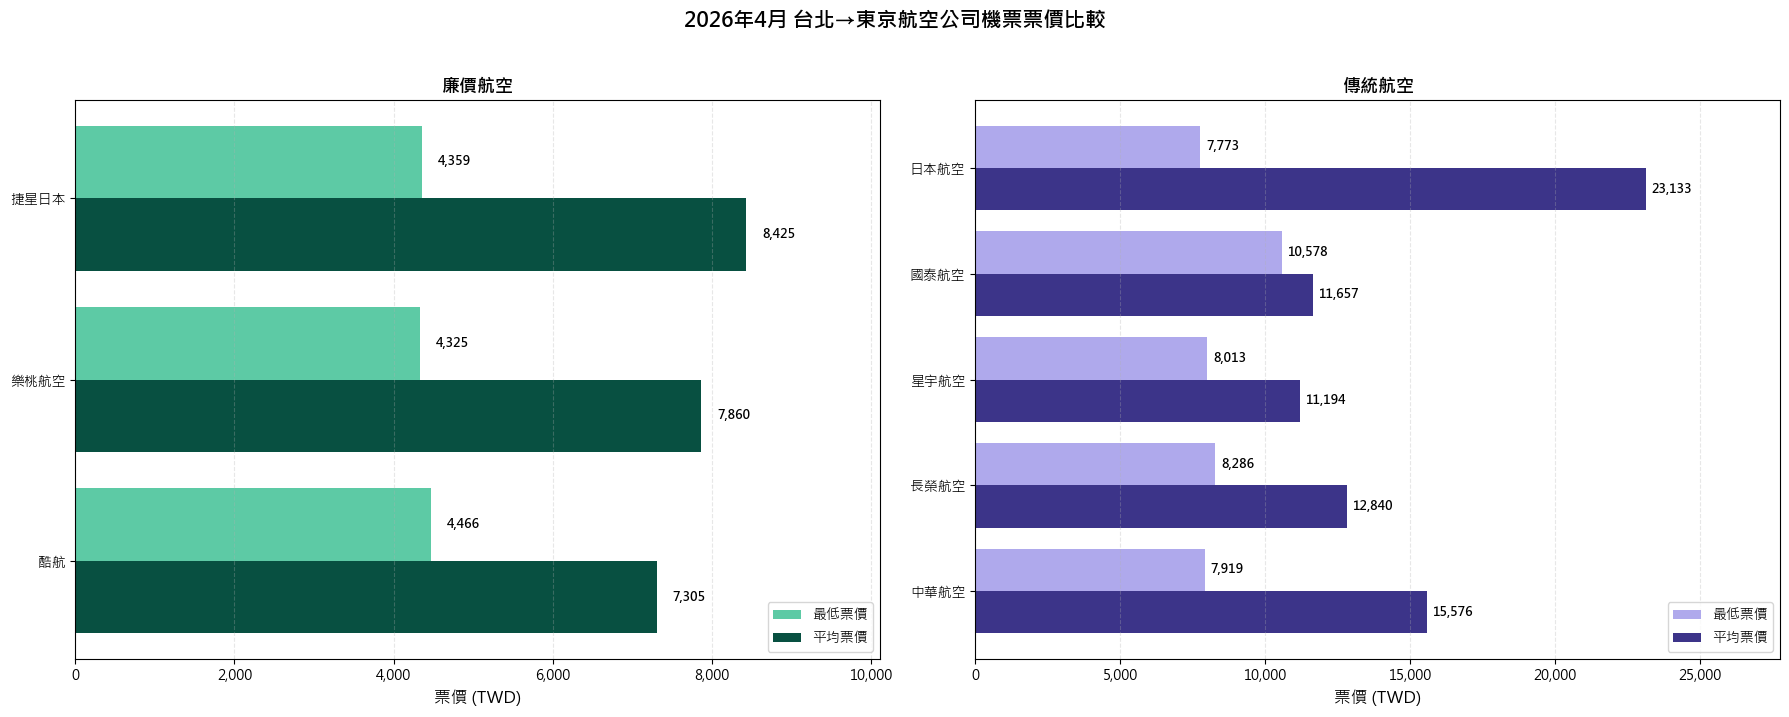

In [15]:
# 2026年4月 台北→東京航空公司機票票價比較

import pandas as pd
import matplotlib.pyplot as plt
import logging

# 環境與中文顯示設定
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
plt.rcParams['font.sans-serif'] = ['Microsoft JhengHei', 'Arial Unicode MS', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False

T_SIZE, L_SIZE, S_SIZE = 16, 12, 10

# 讀取與篩選資料
df = pd.read_csv('台北_東京_經濟艙直飛.csv', encoding='utf-8-sig')
df['date'] = pd.to_datetime(df['date'])
df_april = df[df['date'].dt.month == 4].copy()

# 航空公司分類清單
budget_list = ['酷航', '台灣虎航', '樂桃航空', '捷星日本']
full_list = ['中華航空', '長榮航空', '星宇航空', '國泰航空', '日本航空', '全日空']

#  開始繪製圖表
plt.figure(figsize=(18, 8))

def draw_airline_bar(pos, group_list, title, color_min, color_avg):
    plt.subplot(1, 2, pos)
    group_df = df_april[df_april['airline'].isin(group_list)]
    # 計算統計值並確保順序
    stats = group_df.groupby('airline')['ticket_price'].agg(['min', 'mean']).reindex(group_list).dropna()
    
    y_pos = range(len(stats))
    width = 0.4
    
    # 繪製長條圖
    b1 = plt.barh([p + width/2 for p in y_pos], stats['min'], width, color=color_min, label='最低票價')
    b2 = plt.barh([p - width/2 for p in y_pos], stats['mean'], width, color=color_avg, label='平均票價')
    
    # 在長條上標示價格 
    def add_labels(bars):
        for bar in bars:
            w = bar.get_width()
            plt.text(w + 200, bar.get_y() + bar.get_height()/2, format(int(w), ','), 
                     va='center', fontsize=9, fontweight='bold')
    
    add_labels(b1)
    add_labels(b2)
    
    # 座標軸設定
    plt.yticks(y_pos, stats.index, fontsize=S_SIZE)
    plt.title(title, fontsize=13, fontweight='bold')
    plt.xlabel('票價 (TWD)', fontsize=L_SIZE)
    
    # 設定 X 軸範圍
    plt.xlim(0, stats['mean'].max() * 1.2)
    plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: format(int(x), ',')))
    
    plt.legend(loc='lower right')
    plt.grid(axis='x', linestyle='--', alpha=0.3)

# 執行繪圖
draw_airline_bar(1, budget_list, '廉價航空', '#5DCAA5', '#085041')
draw_airline_bar(2, full_list, '傳統航空', '#AFA9EC', '#3C3489')

# 縮短標題與圖表距離
# y=0.92 讓總標題稍微下移，靠近圖表
plt.suptitle('2026年4月 台北→東京航空公司機票票價比較', fontsize=15, fontweight='bold', y=0.92)

# rect=[左, 下, 右, 上] -> 上邊界調至 0.90，減少標題與子圖間的空隙
plt.tight_layout(rect=[0, 0.03, 1, 0.90])

# 輸出與顯示
plt.savefig('航空公司比較.png', dpi=300)
plt.show()

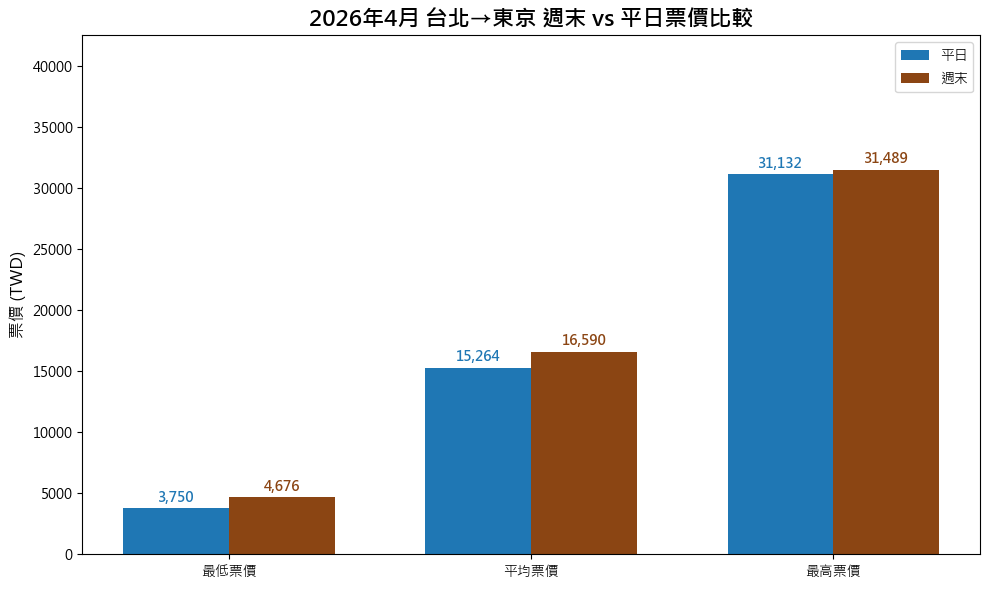

In [18]:
#2026年4月 台北→東京 週末 vs 平日票價比較

import pandas as pd
import matplotlib.pyplot as plt

# 環境與中文顯示設定 
plt.rcParams['font.sans-serif'] = ['Microsoft JhengHei', 'Arial Unicode MS', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False

T_SIZE, L_SIZE, S_SIZE = 16, 12, 10
C_BROWN, C_BLUE = '#8B4513', '#1f77b4'

# 讀取資料與基礎處理 
df_data = pd.read_csv('台北_東京_經濟艙直飛.csv', encoding='utf-8-sig')
df_data['date'] = pd.to_datetime(df_data['date']) # 修正 df_raw 為 df_data

# 篩選 4 月份資料
df = df_data[df_data['date'].dt.month == 4].copy()
df['is_weekend'] = df['date'].dt.dayofweek >= 5

# 週末/平日資料集
df_wd = df[~df['is_weekend']]['ticket_price']
df_we = df[df['is_weekend']]['ticket_price']

# 繪圖
plt.figure(figsize=(10, 6))

labels = ['最低票價', '平均票價', '最高票價']
wd_vals = [df_wd.min(), df_wd.mean(), df_wd.max()]
we_vals = [df_we.min(), df_we.mean(), df_we.max()]

x_pos = [0, 1, 2] 
width = 0.35

# 繪製長條圖
bars_wd = plt.bar([p - width/2 for p in x_pos], wd_vals, width, color=C_BLUE, label='平日')
bars_we = plt.bar([p + width/2 for p in x_pos], we_vals, width, color=C_BROWN, label='週末')

# 數值標籤 
def add_bar_labels(bars, color):
    for bar in bars:
        h = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, h + 200, format(int(h), ','), 
                 ha='center', va='bottom', color=color, fontweight='bold')

add_bar_labels(bars_wd, C_BLUE)
add_bar_labels(bars_we, C_BROWN)

# 圖表裝飾 
plt.title('2026年4月 台北→東京 週末 vs 平日票價比較', fontsize=T_SIZE, fontweight='bold')
plt.ylabel('票價 (TWD)', fontsize=L_SIZE)
plt.xticks(x_pos, labels, fontsize=S_SIZE)
plt.ylim(0, max(we_vals) * 1.35)
plt.legend(loc='upper right')


plt.tight_layout()
plt.savefig('2026年4月 台北→東京 週末 vs 平日票價比較.png', dpi=300)
plt.show()

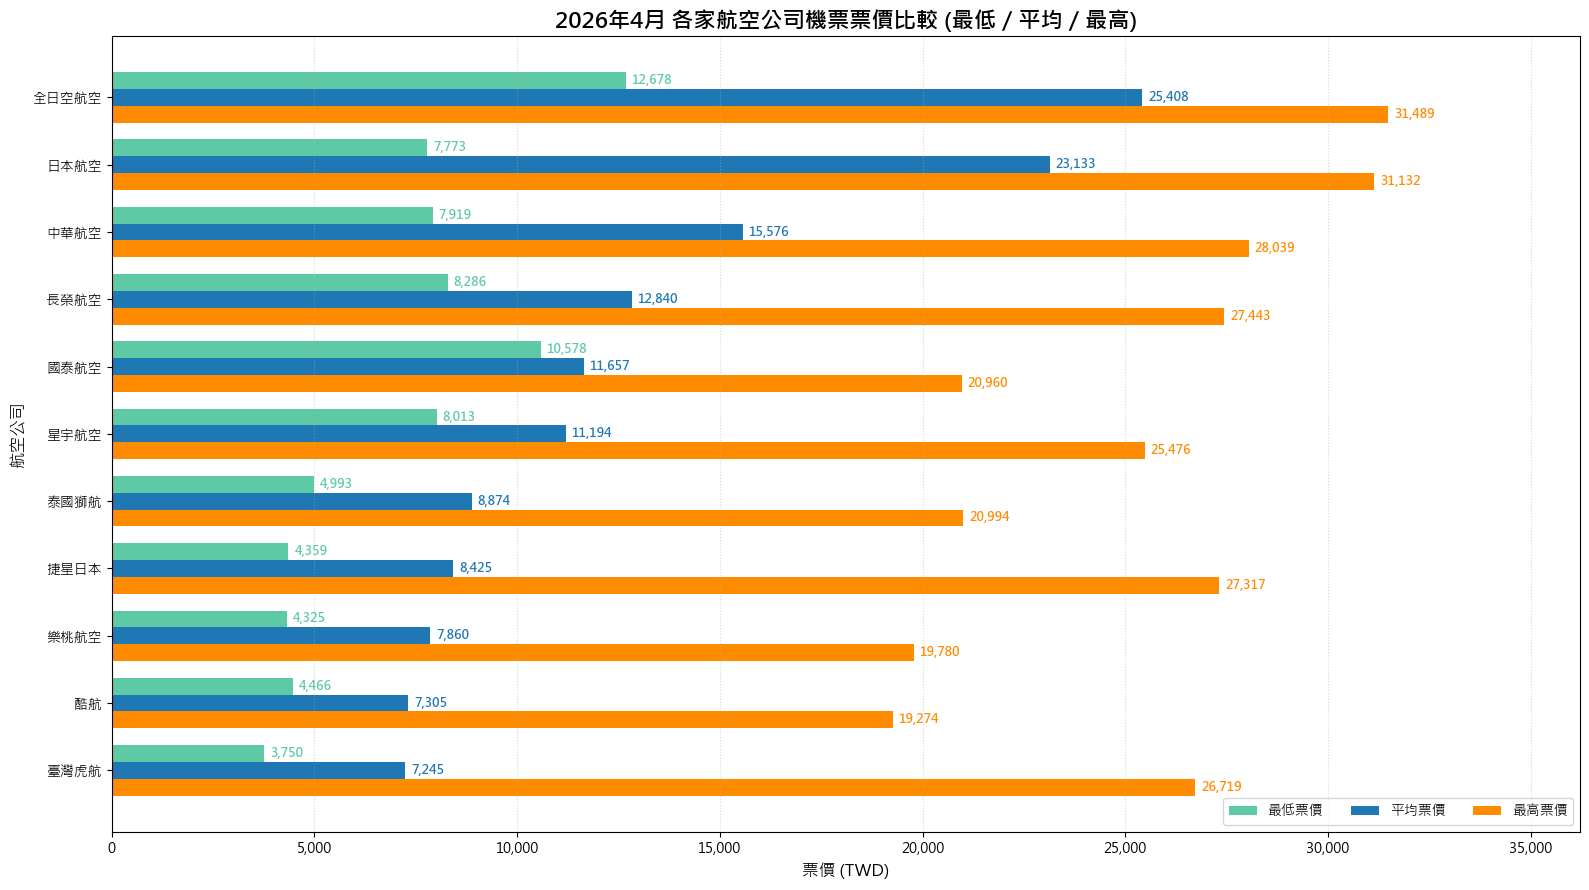

In [22]:
#2026年4月 各家航空公司機票票價比較

import pandas as pd
import matplotlib.pyplot as plt

# 環境與中文顯示設定 (移除 logging 與未使用的 mdates/ticker)
plt.rcParams['font.sans-serif'] = ['Microsoft JhengHei']
plt.rcParams['axes.unicode_minus'] = False

T_SIZE, L_SIZE, S_SIZE = 16, 12, 10
C_LOW = '#5DCAA5'  # 綠色 (最低價)
C_BLUE = '#1f77b4' # 藍色 (平均價)
C_HIGH = '#FF8C00' # 橘色 (最高價)

# 讀取資料與基礎處理 (修正變數名稱錯誤)
df_data = pd.read_csv('台北_東京_經濟艙直飛.csv', encoding='utf-8-sig')
df_data['date'] = pd.to_datetime(df_data['date']) 

# 篩選 4 月份資料
df = df_data[df_data['date'].dt.month == 4].copy()

# 航空公司統計
df_airline = df.groupby('airline')['ticket_price'].agg(['min', 'mean', 'max']).sort_values('mean')

# 繪圖
plt.figure(figsize=(16, 9))

y_pos = range(len(df_airline))
h = 0.25 # 調整長條寬度

# 繪製水平長條圖
b_low = plt.barh([p + h for p in y_pos], df_airline['min'], h, color=C_LOW, label='最低票價')
b_avg = plt.barh(y_pos, df_airline['mean'], h, color=C_BLUE, label='平均票價')
b_hgh = plt.barh([p - h for p in y_pos], df_airline['max'], h, color=C_HIGH, label='最高票價')

# 數值標籤 
def add_h_labels(bars, color):
    for bar in bars:
        w = bar.get_width()
        plt.text(w + 150, bar.get_y() + bar.get_height()/2, format(int(w), ','), 
                 va='center', ha='left', color=color, fontsize=9, fontweight='bold')

add_h_labels(b_low, C_LOW)
add_h_labels(b_avg, C_BLUE)
add_h_labels(b_hgh, C_HIGH)

# 圖表修飾 
plt.title('2026年4月 各家航空公司機票票價比較 (最低／平均／最高)', fontsize=T_SIZE, fontweight='bold')
plt.xlabel('票價 (TWD)', fontsize=L_SIZE)
plt.ylabel('航空公司', fontsize=L_SIZE)
plt.yticks(y_pos, df_airline.index, fontsize=S_SIZE)

# 設定 X 軸範圍
plt.xlim(0, df_airline['max'].max() * 1.15)
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: format(int(x), ',')))

plt.legend(loc='lower right', ncol=3)
plt.grid(axis='x', linestyle=':', alpha=0.5)
plt.tight_layout()
plt.savefig('2026年4月 各家航空公司機票票價比較.png', dpi=300)
plt.show()

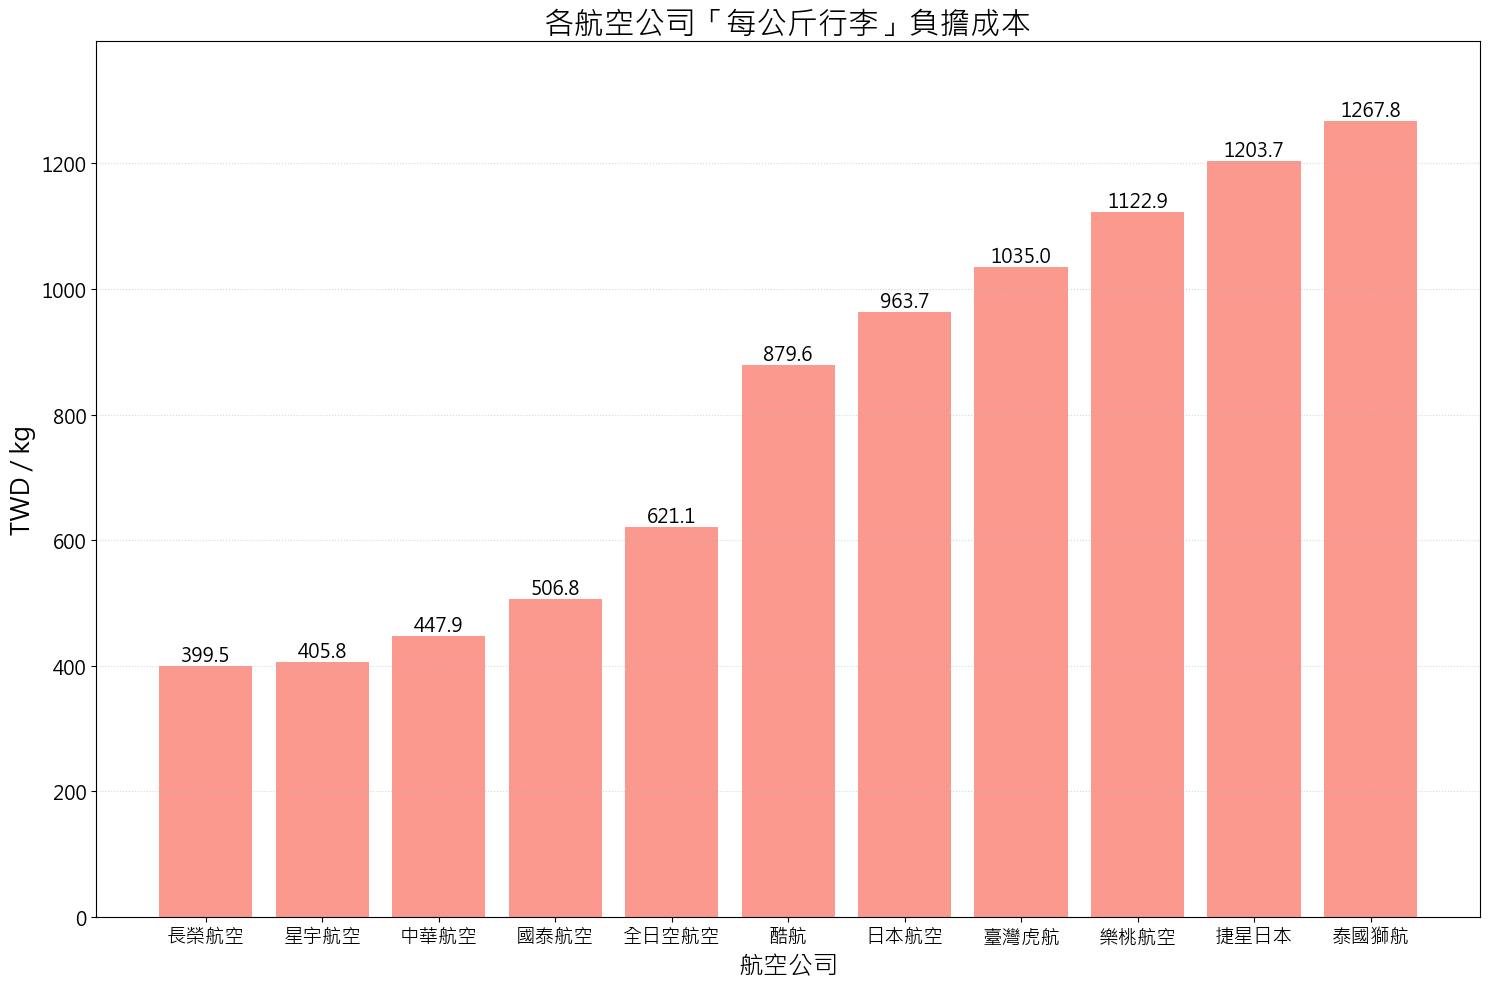

In [24]:
#各航空公司「每公斤行李」負擔成本

import pandas as pd
import matplotlib.pyplot as plt

# 環境設定與資料載入
plt.rcParams['font.sans-serif'] = ['Microsoft JhengHei'] 
plt.rcParams['axes.unicode_minus'] = False

# 讀取資料
df_data = pd.read_csv('台北_東京_經濟艙直飛.csv')
df_data['date'] = pd.to_datetime(df_data['date'])

# 鎖定 4 月份
df_apr = df_data[df_data['date'].dt.month == 4].copy()

#  行李重量量化 (kg)
def get_baggage_kg(b):
    b = str(b)
    if '2 x 23' in b: return 46
    if '30' in b: return 30
    if '23' in b: return 23
    return 7 # 預設手提重量

df_apr['kg'] = df_apr['baggage'].apply(get_baggage_kg)

#  設施量化與總分計算 
# 計算服務總分：統計 amenities 欄位中的單引號數量來判斷設施數
df_apr['服務總分'] = df_apr['amenities'].str.count("'") // 2

#  計算「行李單價」 (票價 / 每公斤)
df_apr['price_per_kg'] = df_apr['ticket_price'] / df_apr['kg']

#  航空類型分類 
LCC_LIST = ['臺灣虎航', '樂桃航空', '酷航', '捷星日本']
df_apr['航空類型'] = df_apr['airline'].apply(lambda x: '廉航' if x in LCC_LIST else '傳統')

# 欄位中文化
df_apr = df_apr.rename(columns={'airline': '航空公司', 'ticket_price': '機票價格'})
# 定義字體大小變數 
T_SIZE = 22  # 圖表大標題
L_SIZE = 18  # 軸標題大小
S_SIZE = 14  # 刻度標籤大小

# 各航空公司「每公斤行李」負擔成本 (長條圖)
plt.figure(figsize=(15, 10))
# 資料由小到大排序
avg_kg_price = df_apr.groupby('航空公司')['price_per_kg'].mean().sort_values()

# 繪製長條圖 
bars = plt.bar(avg_kg_price.index, avg_kg_price.values, color='salmon', alpha=0.8)

# 在長條圖上方標示數字 
for bar in bars:
    height = bar.get_height()
    label_text = '%.1f' % height
    plt.text(bar.get_x() + bar.get_width()/2, height, 
             label_text, 
             ha='center', va='bottom', fontsize=S_SIZE)

# 設定標題與標籤
plt.title('各航空公司「每公斤行李」負擔成本', fontsize=T_SIZE)
plt.xlabel('航空公司', fontsize=L_SIZE)
plt.ylabel('TWD / kg', fontsize=L_SIZE)

# X 軸刻度文字設定為水平 (rotation=0)
plt.xticks(rotation=0, fontsize=S_SIZE) 

plt.yticks(fontsize=S_SIZE)
plt.grid(axis='y', linestyle=':', alpha=0.5)

# 增加頂部空間，避免文字被切掉
plt.ylim(0, max(avg_kg_price.values) * 1.1)
plt.tight_layout()
plt.savefig('行李成本排行.png', dpi=300, bbox_inches='tight')
plt.show()


C:\Users\USER\AppData\Local\Temp\ipykernel_8356\3423019564.py:35: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = plt.boxplot(data, labels=period_list, patch_artist=True)


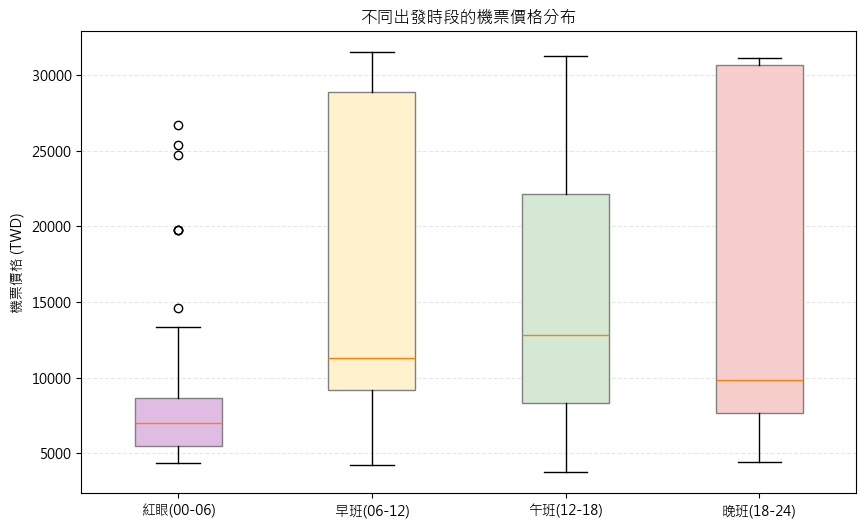

In [25]:
# 不同出發時段的機票價格分布

import pandas as pd
import matplotlib.pyplot as plt

#  環境設定與資料載入
plt.rcParams['font.sans-serif'] = ['Microsoft JhengHei'] 
plt.rcParams['axes.unicode_minus'] = False

df_data = pd.read_csv('台北_東京_經濟艙直飛.csv')
df_data['date'] = pd.to_datetime(df_data['date'])

#  資料篩選與時段處理
df = df_data[df_data['date'].dt.month == 4].copy()

def get_period(t):
    h = int(str(t).split(':')[0])
    if 0 <= h < 6: return '紅眼(00-06)'
    if 6 <= h < 12: return '早班(06-12)'
    if 12 <= h < 18: return '午班(12-18)'
    return '晚班(18-24)'

df['時段'] = df['departure_time'].apply(get_period)

# 3. 繪製時段價格分布圖
plt.figure(figsize=(10, 6))
period_list = ['紅眼(00-06)', '早班(06-12)', '午班(12-18)', '晚班(18-24)']
colors = ['#E0BBE4', '#FFF2CC', '#D5E8D4', '#F8CECC'] 

# 準備各時段的價格數據列表
data = []
for p in period_list:
    price = df[df['時段'] == p]['ticket_price']
    data.append(price)

# 畫箱型圖
bp = plt.boxplot(data, labels=period_list, patch_artist=True)

# 設定顏色與樣式
for i in range(len(bp['boxes'])):
    bp['boxes'][i].set_facecolor(colors[i])
    bp['boxes'][i].set_edgecolor('gray')

plt.title('不同出發時段的機票價格分布')
plt.ylabel('機票價格 (TWD)')
plt.grid(axis='y', linestyle='--', alpha=0.3)

# 儲存圖片
plt.savefig('不同出發時段機票價格分布.png', dpi=300, bbox_inches='tight')
plt.show()

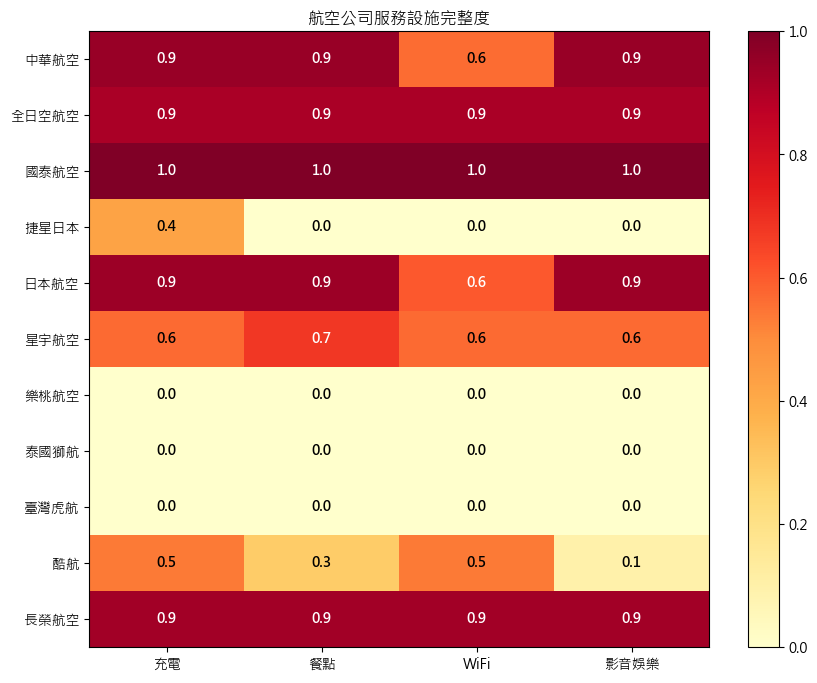

In [26]:
#各航空公司「每公斤行李」平均負擔成本排行
import pandas as pd
import matplotlib.pyplot as plt

#  環境設定與資料載入
plt.rcParams['font.sans-serif'] = ['Microsoft JhengHei'] 
plt.rcParams['axes.unicode_minus'] = False

df_data = pd.read_csv('台北_東京_經濟艙直飛.csv')

# 服務設施統計處理
service_cols = ['充電', '餐點', 'WiFi', '影音娛樂']
df_data['充電'] = df_data['amenities'].apply(lambda x: 1 if 'charging' in str(x) else 0)
df_data['餐點'] = df_data['amenities'].apply(lambda x: 1 if 'dinner' in str(x) else 0)
df_data['WiFi'] = df_data['amenities'].apply(lambda x: 1 if 'wifi' in str(x) else 0)
df_data['影音娛樂'] = df_data['amenities'].apply(lambda x: 1 if 'show' in str(x) else 0)

# 建立矩陣資料
matrix = df_data.groupby('airline')[service_cols].mean()

# 繪製設施矩陣熱力圖
plt.figure(figsize=(10, 8))
im = plt.imshow(matrix, cmap='YlOrRd', aspect='auto')

# 數值標註
for i in range(len(matrix.index)):
    for j in range(len(matrix.columns)):
        val = matrix.iloc[i, j]
        txt_c = 'white' if val > 0.6 else 'black' 
        plt.text(j, i, '%.1f' % val, ha='center', va='center', fontweight='bold', color=txt_c)

# 設定座標軸與標題
plt.xticks(range(len(service_cols)), service_cols)
plt.yticks(range(len(matrix.index)), matrix.index)
plt.title('航空公司服務設施完整度')

# 側邊顏色條
plt.colorbar(im)

# 儲存與顯示
plt.savefig('航空公司服務設施完整度.png', dpi=300, bbox_inches='tight')
plt.show()

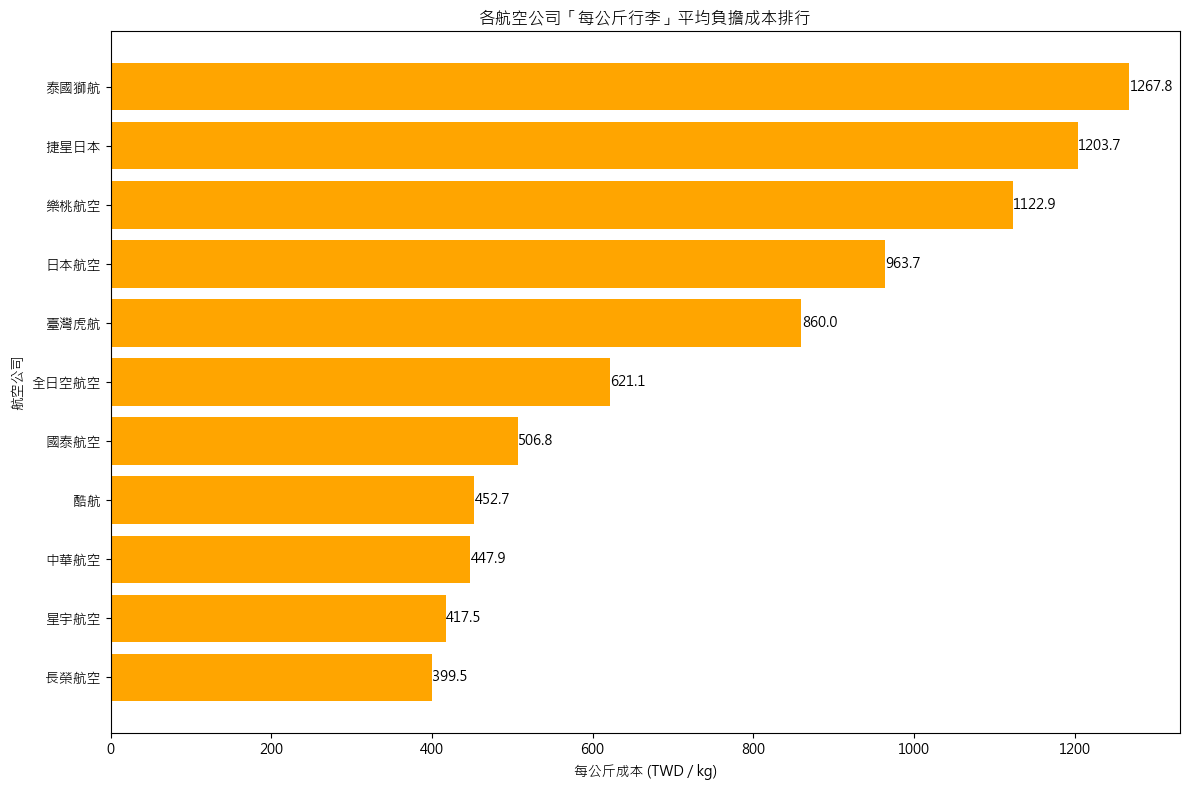

In [28]:
#各航空公司「每公斤行李」平均負擔成本排行

import pandas as pd
import matplotlib.pyplot as plt

# 環境設定與資料載入
plt.rcParams['font.sans-serif'] = ['Microsoft JhengHei'] 
plt.rcParams['axes.unicode_minus'] = False

df = pd.read_csv('台北_東京_經濟艙直飛.csv')

# 行李重量與單價計算
def get_weight(b):
    b = str(b)
    if '2 x 23' in b: return 46
    if '30' in b: return 30
    if '23' in b: return 23
    return 7

df['行李重量_kg'] = df['baggage'].apply(get_weight)
df['每公斤成本'] = df['ticket_price'] / df['行李重量_kg']

# 資料分組與排序 (由低到高)
df_rank = df.groupby('airline')['每公斤成本'].mean().sort_values()

#  繪製水平長條圖
plt.figure(figsize=(12, 8))
bars = plt.barh(df_rank.index, df_rank.values, color='orange')

# 設定標籤與標題
plt.title('各航空公司「每公斤行李」平均負擔成本排行')
plt.xlabel('每公斤成本 (TWD / kg)')
plt.ylabel('航空公司')

# 在長條右側標示數字
for i in range(len(df_rank)):
    v = df_rank.values[i]
    plt.text(v + 0.5, i, '%.1f' % v, va='center', fontsize=10)

# 調整佈局、存檔並顯示
plt.tight_layout()
plt.savefig('各航空公司「每公斤行李」平均負擔成本排行.png', dpi=300, bbox_inches='tight')
plt.show()

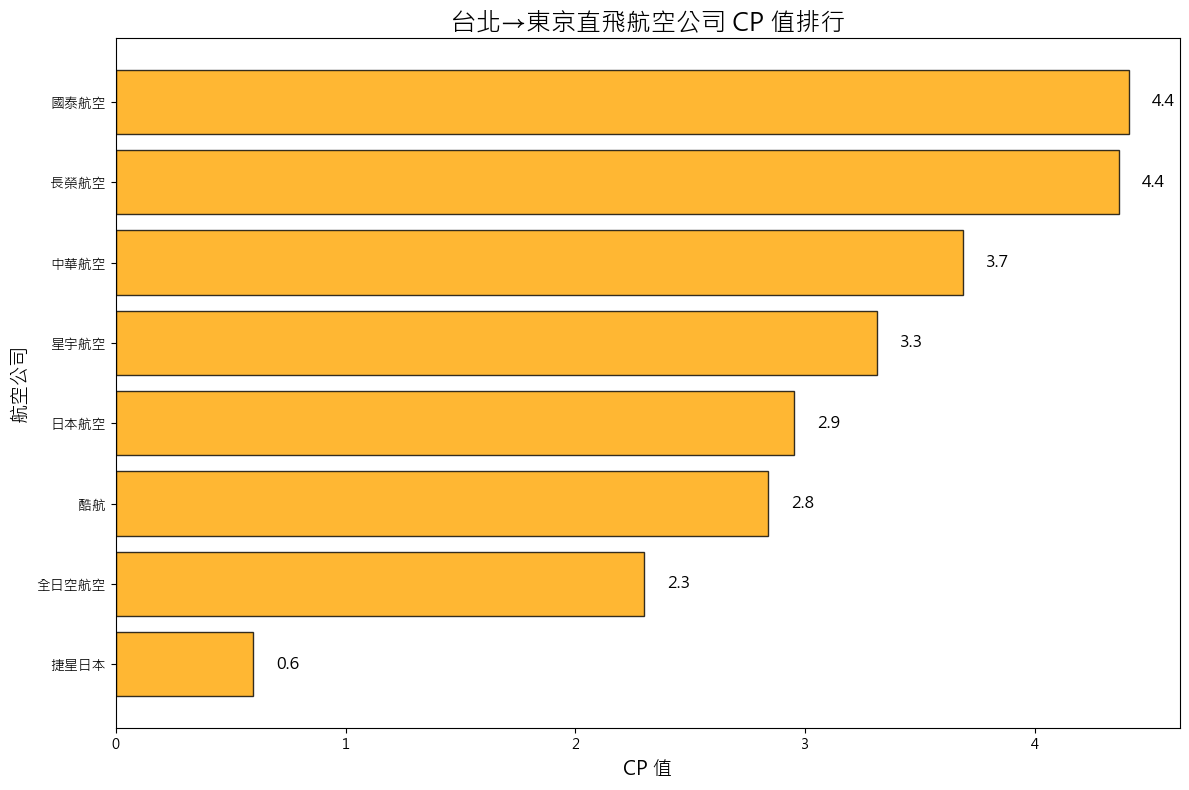

In [34]:
# 台北→東京直飛航空公司 CP 值排行

import pandas as pd
import matplotlib.pyplot as plt

# 環境與字體設定
plt.rcParams['font.sans-serif'] = ['Microsoft JhengHei'] 
plt.rcParams['axes.unicode_minus'] = False

# 讀取資料
df = pd.read_csv('台北_東京_經濟艙直飛.csv')

# CP 值建模計算
# 服務評分：計算設施項目數
df['service_score'] = df['amenities'].str.count("'") // 2

# 行李評分
def get_bag_score(b):
    b = str(b)
    if '2 x 23' in b or '46' in b: return 2
    if '23' in b or '30' in b: return 1
    return 0
df['baggage_score'] = df['baggage'].apply(get_bag_score)

# CP 值公式：(服務+行李) / (價格/10000)
df['cp_index'] = (df['service_score'] + df['baggage_score']) / (df['ticket_price'] / 10000)

# 資料分組與排序 (降序排列)
df_rank = df.groupby('airline')['cp_index'].mean()
df_rank = df_rank[df_rank > 0].dropna().sort_values(ascending=True)

# 繪製水平長條圖
plt.figure(figsize=(12, 8))
bars = plt.barh(df_rank.index, df_rank.values, color='orange', edgecolor='black', alpha=0.8)

# 標示數值 (水平圖：x 軸為寬度 width，y 軸為索引 i)
for i, v in enumerate(df_rank.values):
    plt.text(v + 0.1, i, '%.1f' % v, va='center', fontsize=12)

plt.title('台北→東京直飛航空公司 CP 值排行', fontsize=18)
plt.xlabel('CP 值', fontsize=14)
plt.ylabel('航空公司', fontsize=14)

plt.tight_layout()
plt.savefig('plot_1_CP值排行.png', dpi=300, bbox_inches='tight')
plt.show()

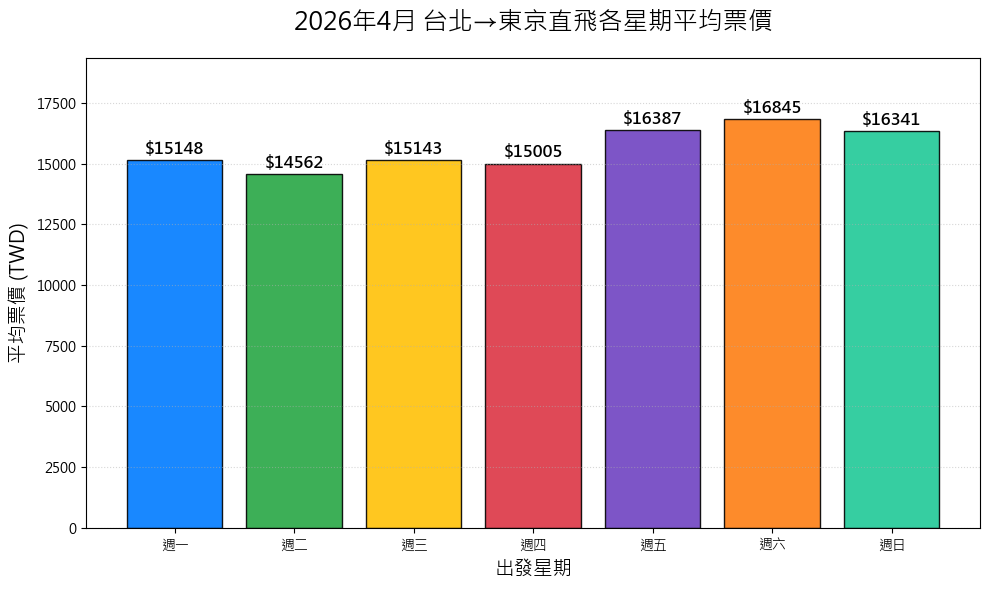

In [33]:
# 2026年4月 台北→東京直飛各星期平均票價

import pandas as pd
import matplotlib.pyplot as plt

# 基礎設定與環境
plt.rcParams['font.sans-serif'] = ['Microsoft JhengHei'] 
plt.rcParams['axes.unicode_minus'] = False

# 讀取資料並篩選 4 月份
df = pd.read_csv('台北_東京_經濟艙直飛.csv')
df['date'] = pd.to_datetime(df['date'])
df_apr = df[df['date'].dt.month == 4].copy()

# 計算星期（0=Mon, 6=Sun）
df_apr['weekday'] = df_apr['date'].dt.dayofweek
weekday_avg = df_apr.groupby('weekday')['ticket_price'].mean()
week_labels = ['週一', '週二', '週三', '週四', '週五', '週六', '週日']

# 開始繪圖
plt.figure(figsize=(10, 6))

# 配色設定
vivid_colors = ['#007bff', '#28a745', '#ffc107', '#dc3545', '#6f42c1', '#fd7e14', '#20c997']

# 繪製長條圖
bars = plt.bar(week_labels, weekday_avg, color=vivid_colors, edgecolor='black', alpha=0.9)

# 在長條上方標註金額
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 100, 
             '$%d' % int(height), ha='center', va='bottom', fontsize=12, fontweight='bold')

# 設定標題與座標軸標籤
plt.title('2026年4月 台北→東京直飛各星期平均票價', fontsize=18, pad=20)
plt.xlabel('出發星期', fontsize=14)  
plt.ylabel('平均票價 (TWD)', fontsize=14)

plt.grid(axis='y', linestyle=':', alpha=0.5)
plt.ylim(0, max(weekday_avg) * 1.15)

# 存檔與顯示
plt.tight_layout()
plt.savefig('2026年4月_各星期平均票價.png', dpi=300, bbox_inches='tight')
plt.show()